# Proyek Data Science: Sistem Optimasi Reorder Point (ROP) & Safety Stock Dinamis
## Tahap 1: Exploratory Data Analysis (EDA), Variabilitas Lead Time & Permintaan, serta Segmentasi ABC/XYZ
**Domain Bisnis:** Supply Chain & Inventory Control - Fashion Vintage 90s (Shopee Store)  
**Dataset:** `dataset_supply_chain_pakaian_90an_shopee.xlsx`  
**Periode Analisis:** 21 September 2026 s/d 20 Oktober 2026 (30 Hari Transaksi)

---

### Tujuan Analisis Tahap 1:
1. **Business & Data Understanding:** Memetakan relasi 5 tabel utama (`Produk_Master`, `Pemasok`, `Pembelian`, `Pesanan`, `Persediaan`).
2. **Sales Velocity & Demand Variability:** Menghitung rata-rata harian ($\mu_d$), deviasi standar harian ($\sigma_d$), dan koefisien variasi ($CV_d$) per SKU.
3. **Supplier Reliability Analysis:** Menganalisis variabilitas lead time aktual vs target ($\sigma_{LT}$) dan rasio keterlambatan per pemasok.
4. **Segmentasi Portofolio ABC / XYZ:**
   - **Analisis ABC:** Mengelompokkan SKU berdasarkan kontribusi nilai omzet kumulatif (Pareto 80/15/5).
   - **Analisis XYZ:** Mengelompokkan SKU berdasarkan tingkat kestabilan/volatilitas permintaan harian.
5. **Matriks 9 Kuadran & Kebijakan Service Level:** Menentukan target *Service Level* ($Z$-score) yang optimal untuk kalkulasi *Safety Stock* dinamis di Tahap 2.
6. **Audit Inventaris Eksisting:** Mengevaluasi posisi stok akhir vs titik ROP eksisting untuk mendeteksi SKU kritis yang berisiko *stockout*.

In [1]:
from IPython.display import display
# Import pustaka utama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Konfigurasi visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 110

# Palet warna profesional Supply Chain
PRIMARY_COLOR = '#1f77b4'
ACCENT_COLOR = '#ff7f0e'
ALERT_COLOR = '#d62728'
SUCCESS_COLOR = '#2ca02c'
NEUTRAL_COLOR = '#7f7f7f'

print("Pustaka berhasil diimpor & konfigurasi visualisasi aktif.")

Pustaka berhasil diimpor & konfigurasi visualisasi aktif.


---
## 1. Pemuatan & Pemeriksaan Struktur Data (Data Ingestion & Integrity Check)
Kita membaca ke-5 lembar kerja dari dataset Excel ke dalam DataFrame terpisah dan memeriksa integritas relasi antar tabel.

In [2]:
# Path dataset Excel
EXCEL_PATH = 'dataset_supply_chain_pakaian_90an_shopee.xlsx'

# Membaca seluruh sheet
df_produk = pd.read_excel(EXCEL_PATH, sheet_name='Produk_Master')
df_pemasok = pd.read_excel(EXCEL_PATH, sheet_name='Pemasok')
df_pembelian = pd.read_excel(EXCEL_PATH, sheet_name='Pembelian')
df_pesanan = pd.read_excel(EXCEL_PATH, sheet_name='Pesanan')
df_persediaan = pd.read_excel(EXCEL_PATH, sheet_name='Persediaan')
df_retur = pd.read_excel(EXCEL_PATH, sheet_name='Retur')

# Ringkasan dimensi dataset
summary_dim = pd.DataFrame({
    'Tabel / Sheet': ['Produk_Master', 'Pemasok', 'Pembelian', 'Pesanan', 'Persediaan', 'Retur'],
    'Jumlah Baris': [len(df_produk), len(df_pemasok), len(df_pembelian), len(df_pesanan), len(df_persediaan), len(df_retur)],
    'Jumlah Kolom': [df_produk.shape[1], df_pemasok.shape[1], df_pembelian.shape[1], df_pesanan.shape[1], df_persediaan.shape[1], df_retur.shape[1]],
    'Entitas Utama': ['SKU Produk', 'Partner Supplier', 'Purchase Order (PO)', 'Item Pesanan Pelanggan', 'Posisi Stok Bulanan', 'Retur Barang']
})

print("=== RINGKASAN DATASET SUPPLY CHAIN ===")
display(summary_dim)

# Rentang tanggal pesanan
tgl_min = df_pesanan['Tanggal_Order'].min().strftime('%d %b %Y')
tgl_max = df_pesanan['Tanggal_Order'].max().strftime('%d %b %Y')
total_omzet = df_pesanan['Omzet_Kotor_Rp'].sum()
total_unit_terjual = df_pesanan['Qty'].sum()

print(f"\nRentang Periode Pesanan: {tgl_min} s/d {tgl_max} ({(df_pesanan['Tanggal_Order'].max() - df_pesanan['Tanggal_Order'].min()).days + 1} hari kalender)")
print(f"Total Unit Terjual: {total_unit_terjual:,} pcs | Total Omzet Kotor: Rp {total_omzet:,.0f}")

=== RINGKASAN DATASET SUPPLY CHAIN ===


,Tabel / Sheet,Jumlah Baris,Jumlah Kolom,Entitas Utama
0,Produk_Master,15,13,SKU Produk
1,Pemasok,6,8,Partner Supplier
2,Pembelian,26,11,Purchase Order (PO)
3,Pesanan,86,18,Item Pesanan Pelanggan
4,Persediaan,15,14,Posisi Stok Bulanan
5,Retur,5,8,Retur Barang



Rentang Periode Pesanan: 21 Sep 2026 s/d 20 Oct 2026 (30 hari kalender)
Total Unit Terjual: 101 pcs | Total Omzet Kotor: Rp 13,152,500


---
## 2. Analisis Kecepatan Penjualan (*Sales Velocity*) & Variabilitas Permintaan Harian
Dalam penentuan Safety Stock ($SS$) dinamis, kita membutuhkan estimasi deviasi standar permintaan harian ($\sigma_d$).  
Langkah:
1. Agregasi penjualan harian untuk setiap SKU selama periode 30 hari penuh (termasuk hari di mana penjualan = 0).
2. Hitung statistik deskriptif harian: rata-rata harian ($\mu_d$), deviasi standar harian ($\sigma_d$), dan *Coefficient of Variation* ($CV_d = \sigma_d / \mu_d$).

In [3]:
# Buat rentang tanggal lengkap selama periode observasi (30 hari)
date_range = pd.date_range(start=df_pesanan['Tanggal_Order'].min(), end=df_pesanan['Tanggal_Order'].max(), freq='D')
all_skus = df_produk['SKU'].unique()

# Grid perkalian silang (Tanggal x SKU) untuk menangkap hari tanpa penjualan (Demand = 0)
idx = pd.MultiIndex.from_product([date_range, all_skus], names=['Tanggal_Order', 'SKU'])
grid_df = pd.DataFrame(index=idx).reset_index()

# Agregasi penjualan aktual per hari per SKU
daily_actual = df_pesanan.groupby(['Tanggal_Order', 'SKU'])['Qty'].sum().reset_index()

# Merge ke grid lengkap, isi NaN dengan 0
daily_demand_full = pd.merge(grid_df, daily_actual, on=['Tanggal_Order', 'SKU'], how='left').fillna({'Qty': 0})
daily_demand_full.rename(columns={'Qty': 'Demand_Harian'}, inplace=True)

# Hitung metrik demand per SKU
demand_metrics = daily_demand_full.groupby('SKU').agg(
    Total_Terjual=('Demand_Harian', 'sum'),
    Hari_Ada_Penjualan=('Demand_Harian', lambda x: (x > 0).sum()),
    Demand_Mean_Harian=('Demand_Harian', 'mean'),
    Demand_Std_Harian=('Demand_Harian', 'std'),
    Demand_Max_Harian=('Demand_Harian', 'max')
).reset_index()

# Hitung Koefisien Variasi Demand (CV_d)
demand_metrics['Demand_CV'] = demand_metrics['Demand_Std_Harian'] / demand_metrics['Demand_Mean_Harian']

# Gabungkan dengan info Produk Master
demand_profile = pd.merge(
    df_produk[['SKU', 'Nama_Produk', 'Kategori', 'Tipe_Pasokan', 'Harga_Jual_Rp', 'Modal_Unit_Rp']],
    demand_metrics,
    on='SKU'
)

# Hitung Total Omzet & Margin
demand_profile['Total_Omzet_Rp'] = demand_profile['Total_Terjual'] * demand_profile['Harga_Jual_Rp']
demand_profile['Total_Margin_Rp'] = demand_profile['Total_Terjual'] * (demand_profile['Harga_Jual_Rp'] - demand_profile['Modal_Unit_Rp'])

demand_profile = demand_profile.sort_values(by='Total_Omzet_Rp', ascending=False).reset_index(drop=True)

print("=== PROFIL DEMAND & VARIABILITAS PENJUALAN PER SKU ===")
display(demand_profile[['SKU', 'Nama_Produk', 'Tipe_Pasokan', 'Total_Terjual', 'Demand_Mean_Harian', 'Demand_Std_Harian', 'Demand_CV', 'Total_Omzet_Rp']].head(10))

=== PROFIL DEMAND & VARIABILITAS PENJUALAN PER SKU ===


,SKU,Nama_Produk,Tipe_Pasokan,Total_Terjual,Demand_Mean_Harian,Demand_Std_Harian,Demand_CV,Total_Omzet_Rp
0,V90-CGO-001,Celana Cargo 90s,Restockable,14.0,0.466667,0.776079,1.663027,2226000.0
1,V90-SWT-001,Crewneck Colorblock,Restockable,11.0,0.366667,0.556053,1.516509,1529000.0
2,V90-JNS-001,Jeans Straight Denim,Restockable,9.0,0.300000,0.595963,1.986545,1521000.0
3,V90-FLN-001,Kemeja Flanel Kotak,Restockable,13.0,0.433333,0.817200,1.885847,1417000.0
4,V90-TRK-001,Track Jacket Retro,Restockable,7.0,0.233333,0.568321,2.435660,1253000.0
5,V90-TEE-003,Raglan Baseball Tee,Restockable,10.0,0.333333,0.660895,1.982684,950000.0
6,V90-SRT-001,Shorts Denim,Restockable,8.0,0.266667,0.449776,1.686662,792000.0
7,V90-TEE-002,Kaos Washed Boxy,Restockable,8.0,0.266667,0.449776,1.686662,639200.0
8,V90-WND-001,Windbreaker Colorblock,One-off Vintage,4.0,0.133333,0.434172,3.256294,636000.0
9,V90-TEE-001,Kaos Graphic Grunge,Restockable,7.0,0.233333,0.504007,2.160030,629300.0


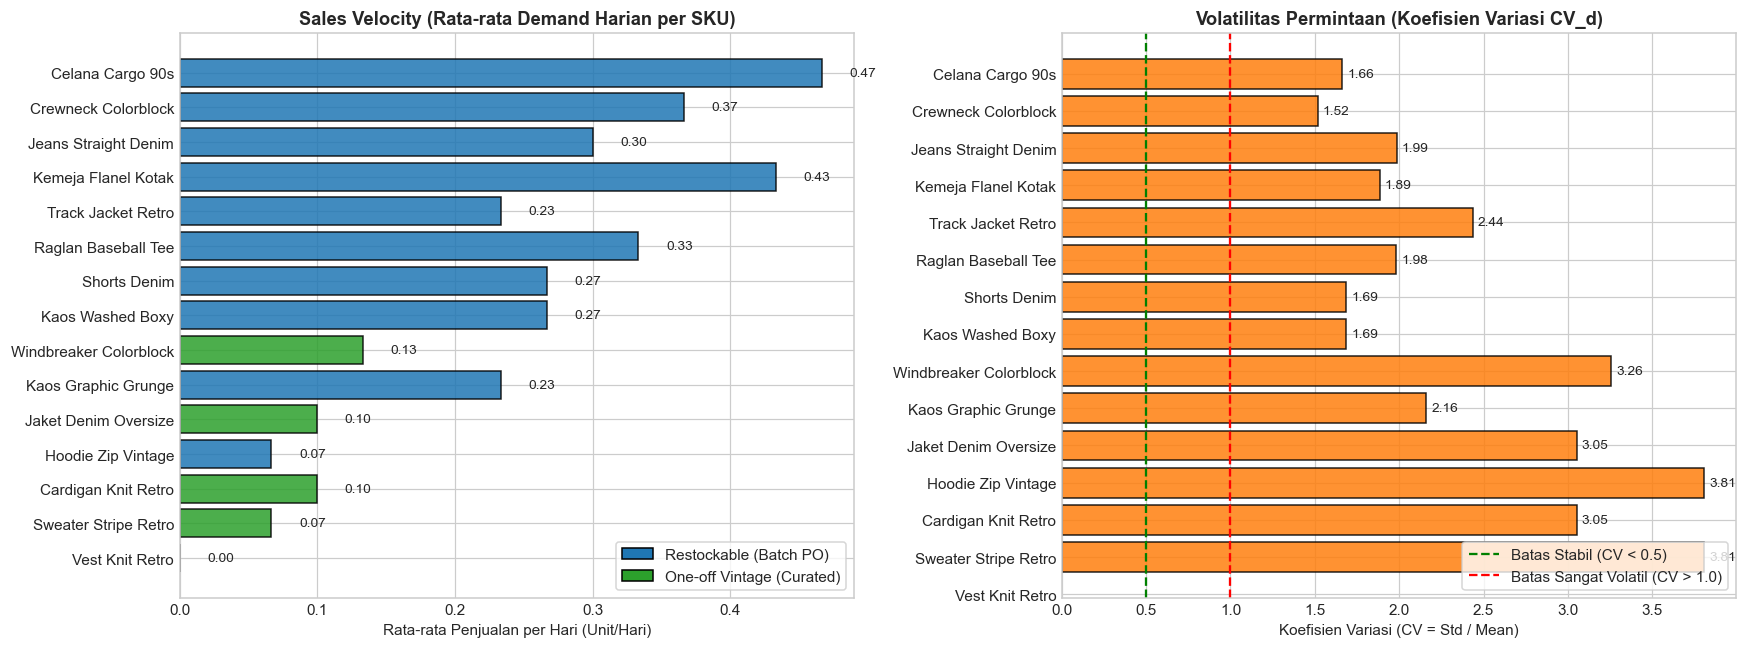

In [4]:
# Visualisasi Profil Demand: Mean Harian & CV per SKU
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Rata-rata Penjualan Harian per SKU
colors = ['#1f77b4' if t == 'Restockable' else '#2ca02c' for t in demand_profile['Tipe_Pasokan']]
bars1 = axes[0].barh(demand_profile['Nama_Produk'], demand_profile['Demand_Mean_Harian'], color=colors, edgecolor='black', alpha=0.85)
axes[0].set_xlabel('Rata-rata Penjualan per Hari (Unit/Hari)')
axes[0].set_title('Sales Velocity (Rata-rata Demand Harian per SKU)')
axes[0].invert_yaxis()

# Tambahkan label nilai
for bar in bars1:
    width = bar.get_width()
    axes[0].text(width + 0.02, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va='center', fontsize=9)

# Legend tipe pasokan
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', edgecolor='black', label='Restockable (Batch PO)'),
    Patch(facecolor='#2ca02c', edgecolor='black', label='One-off Vintage (Curated)')
]
axes[0].legend(handles=legend_elements, loc='lower right', frameon=True)

# Plot 2: Koefisien Variasi (CV_d) - Tingkat Fluktuasi
bars2 = axes[1].barh(demand_profile['Nama_Produk'], demand_profile['Demand_CV'], color='#ff7f0e', edgecolor='black', alpha=0.85)
axes[1].axvline(0.5, color='green', linestyle='--', linewidth=1.5, label='Batas Stabil (CV < 0.5)')
axes[1].axvline(1.0, color='red', linestyle='--', linewidth=1.5, label='Batas Sangat Volatil (CV > 1.0)')
axes[1].set_xlabel('Koefisien Variasi (CV = Std / Mean)')
axes[1].set_title('Volatilitas Permintaan (Koefisien Variasi CV_d)')
axes[1].invert_yaxis()
axes[1].legend(loc='lower right', frameon=True)

for bar in bars2:
    width = bar.get_width()
    axes[1].text(width + 0.03, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 3. Analisis Kinerja Pemasok & Variabilitas Lead Time ($\sigma_{LT}$)
Keterlambatan pengiriman dari supplier adalah penyebab utama *stockout* tak terduga.  
Dari 26 transaksi Purchase Order (`Pembelian`), kita menganalisis:
- Selisih Lead Time ($\Delta LT = Lead\_Time\_Aktual - Lead\_Time\_Target$).
- Standar deviasi Lead Time ($\sigma_{LT}$) untuk setiap supplier.
- Tingkat keterlambatan (*Late Delivery Rate*).

In [5]:
# Gabungkan transaksi Pembelian dengan data Pemasok
df_po_analysis = pd.merge(
    df_pembelian,
    df_pemasok[['Supplier_ID', 'Nama_Pemasok', 'Kota', 'Lead_Time_Target_Hari', 'MOQ_Unit', 'Rating_Internal_5']],
    on='Supplier_ID',
    suffixes=('', '_Supp')
)

# Hitung deviasi Lead Time
df_po_analysis['Lead_Time_Diff'] = df_po_analysis['Lead_Time_Aktual_Hari'] - df_po_analysis['Lead_Time_Target_Hari']
df_po_analysis['Is_Late'] = df_po_analysis['Lead_Time_Diff'] > 0

# Ringkasan metrik performa per supplier
supplier_performance = df_po_analysis.groupby(['Supplier_ID', 'Nama_Pemasok', 'Kota']).agg(
    Total_PO=('PO_ID', 'count'),
    Total_Unit_Dipesan=('Qty_Dipesan', 'sum'),
    Lead_Time_Target=('Lead_Time_Target_Hari', 'first'),
    Lead_Time_Aktual_Mean=('Lead_Time_Aktual_Hari', 'mean'),
    Lead_Time_Std=('Lead_Time_Aktual_Hari', 'std'),
    Max_Delay_Hari=('Lead_Time_Diff', 'max'),
    Late_PO_Count=('Is_Late', 'sum'),
    Total_Qty_Rusak=('Qty_Rusak', 'sum')
).reset_index()

# Hitung On-Time Delivery Rate & Late Rate
supplier_performance['Late_Rate_%'] = (supplier_performance['Late_PO_Count'] / supplier_performance['Total_PO']) * 100
supplier_performance['On_Time_Rate_%'] = 100 - supplier_performance['Late_Rate_%']
supplier_performance['Lead_Time_Std'] = supplier_performance['Lead_Time_Std'].fillna(0.0)

print("=== EVALUASI PERFORMA & KEANDALAN LEAD TIME PEMASOK ===")
display(supplier_performance[['Supplier_ID', 'Nama_Pemasok', 'Kota', 'Total_PO', 'Lead_Time_Target', 'Lead_Time_Aktual_Mean', 'Lead_Time_Std', 'Max_Delay_Hari', 'Late_Rate_%']])

# Total statistik keseluruhan lead time
overall_lt_target = df_po_analysis['Lead_Time_Target_Hari'].mean()
overall_lt_actual = df_po_analysis['Lead_Time_Aktual_Hari'].mean()
overall_lt_std = df_po_analysis['Lead_Time_Aktual_Hari'].std()
overall_late_rate = (df_po_analysis['Is_Late'].sum() / len(df_po_analysis)) * 100

print(f"\nStatistik Agregat PO:")
print(f"- Rata-rata Target Lead Time : {overall_lt_target:.2f} hari")
print(f"- Rata-rata Aktual Lead Time : {overall_lt_actual:.2f} hari")
print(f"- Standar Deviasi Lead Time (sigma_LT) : {overall_lt_std:.2f} hari")
print(f"- Persentase PO Terlambat    : {overall_late_rate:.1f}% ({df_po_analysis['Is_Late'].sum()} dari {len(df_po_analysis)} PO)")

=== EVALUASI PERFORMA & KEANDALAN LEAD TIME PEMASOK ===


,Supplier_ID,Nama_Pemasok,Kota,Total_PO,Lead_Time_Target,Lead_Time_Aktual_Mean,Lead_Time_Std,Max_Delay_Hari,Late_Rate_%
0,SUP-001,Garasi Vintage Supply,Bandung,6,8,7.500000,2.073644,2,33.333333
1,SUP-002,Studio Washed Apparel,Tangerang,8,6,7.125000,2.531939,4,75.000000
2,SUP-003,Denim Rewear Hub,Jakarta,4,9,9.000000,2.309401,2,50.000000
3,SUP-004,Flanel Archive,Bandung,1,8,8.000000,0.000000,0,0.000000
4,SUP-005,Retro Outerwear Select,Depok,4,10,10.750000,2.061553,3,75.000000
5,SUP-006,Knit Revival,Solo,3,10,10.333333,2.081666,2,66.666667



Statistik Agregat PO:
- Rata-rata Target Lead Time : 8.08 hari
- Rata-rata Aktual Lead Time : 8.46 hari
- Standar Deviasi Lead Time (sigma_LT) : 2.50 hari
- Persentase PO Terlambat    : 57.7% (15 dari 26 PO)


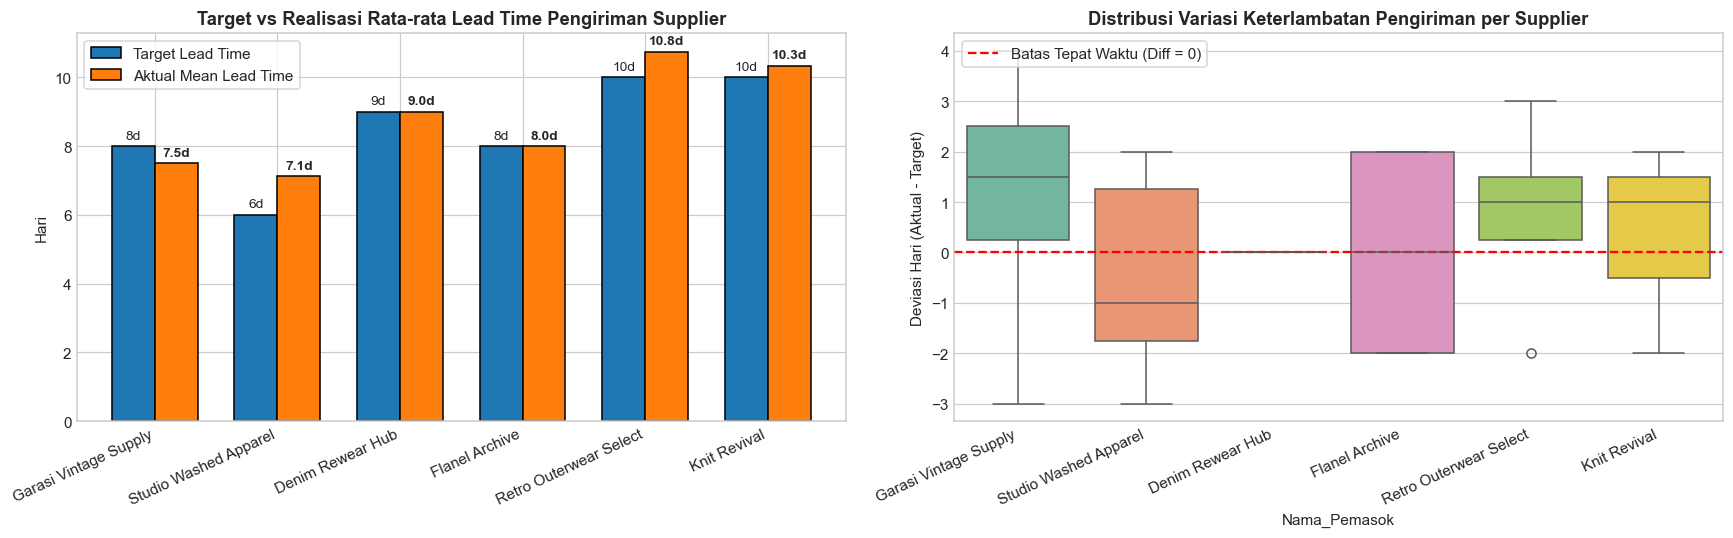

In [6]:
# Visualisasi Lead Time Target vs Aktual per Supplier
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Bar chart perbandingan Target vs Rata-rata Aktual
x = np.arange(len(supplier_performance))
width = 0.35

rects1 = axes[0].bar(x - width/2, supplier_performance['Lead_Time_Target'], width, label='Target Lead Time', color='#1f77b4', edgecolor='black')
rects2 = axes[0].bar(x + width/2, supplier_performance['Lead_Time_Aktual_Mean'], width, label='Aktual Mean Lead Time', color='#ff7f0e', edgecolor='black')

axes[0].set_ylabel('Hari')
axes[0].set_title('Target vs Realisasi Rata-rata Lead Time Pengiriman Supplier')
axes[0].set_xticks(x)
axes[0].set_xticklabels(supplier_performance['Nama_Pemasok'], rotation=25, ha='right')
axes[0].legend(frameon=True)

# Tambahkan label angka
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.0f}d', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}d', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 2: Boxplot sebaran deviasi lead time
sns.boxplot(data=df_po_analysis, x='Nama_Pemasok', y='Lead_Time_Diff', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5, label='Batas Tepat Waktu (Diff = 0)')
axes[1].set_ylabel('Deviasi Hari (Aktual - Target)')
axes[1].set_title('Distribusi Variasi Keterlambatan Pengiriman per Supplier')
axes[1].set_xticklabels(supplier_performance['Nama_Pemasok'], rotation=25, ha='right')
axes[1].legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

---
## 4. Segmentasi Portofolio Inventaris: Matriks ABC - XYZ
Segmentasi portofolio merupakan fondasi dari manajemen stok modern (*differentiated inventory strategy*):
- **Klasifikasi ABC (Prinsip Pareto):**
  - **Kelas A:** Kontributor ~80% dari total omzet kumulatif (SKU paling bernilai secara finansial).
  - **Kelas B:** Kontributor ~15% berikutnya (nilai omzet menengah).
  - **Kelas C:** Kontributor ~5% sisanya (SKU ekor panjang / *long-tail*).
- **Klasifikasi XYZ (Variabilitas Permintaan):**
  - **Kelas X ($CV < 0.5$):** Permintaan stabil, estimasi mudah diprediksi.
  - **Kelas Y ($0.5 \le CV \le 1.0$):** Permintaan berfluktuasi moderat.
  - **Kelas Z ($CV > 1.0$):** Permintaan sangat bergejolak (*lumpy/intermittent*).

In [7]:
# 1. Klasifikasi ABC berdasarkan Omzet Kumulatif
demand_profile = demand_profile.sort_values(by='Total_Omzet_Rp', ascending=False).reset_index(drop=True)
total_rev = demand_profile['Total_Omzet_Rp'].sum()

demand_profile['Omzet_Share_%'] = (demand_profile['Total_Omzet_Rp'] / total_rev) * 100
demand_profile['Omzet_Kumulatif_%'] = demand_profile['Omzet_Share_%'].cumsum()

def assign_abc(cum_share):
    if cum_share <= 80.0:
        return 'A'
    elif cum_share <= 95.0:
        return 'B'
    else:
        return 'C'

demand_profile['Kategori_ABC'] = demand_profile['Omzet_Kumulatif_%'].apply(assign_abc)

# 2. Klasifikasi XYZ berdasarkan Koefisien Variasi (CV_d)
def assign_xyz(cv):
    if cv < 0.5:
        return 'X'
    elif cv <= 1.0:
        return 'Y'
    else:
        return 'Z'

demand_profile['Kategori_XYZ'] = demand_profile['Demand_CV'].apply(assign_xyz)

# Gabungkan menjadi Matriks 9 Kuadran
demand_profile['Segmen_ABC_XYZ'] = demand_profile['Kategori_ABC'] + demand_profile['Kategori_XYZ']

# Tetapkan Target Service Level berdasarkan kuadran
service_level_map = {
    'AX': 0.98, 'AY': 0.98, 'AZ': 0.95,
    'BX': 0.95, 'BY': 0.93, 'BZ': 0.90,
    'CX': 0.90, 'CY': 0.88, 'CZ': 0.85
}
from scipy.stats import norm

demand_profile['Target_Service_Level_%'] = demand_profile['Segmen_ABC_XYZ'].map(service_level_map) * 100
demand_profile['Z_Factor'] = demand_profile['Segmen_ABC_XYZ'].map(lambda k: norm.ppf(service_level_map.get(k, 0.95)))

print("=== HASIL SEGMENTASI ABC-XYZ & KEBIJAKAN SERVICE LEVEL ===")
display(demand_profile[[
    'SKU', 'Nama_Produk', 'Tipe_Pasokan', 'Total_Omzet_Rp', 'Omzet_Share_%', 'Omzet_Kumulatif_%', 
    'Kategori_ABC', 'Demand_CV', 'Kategori_XYZ', 'Segmen_ABC_XYZ', 'Target_Service_Level_%', 'Z_Factor'
]])

=== HASIL SEGMENTASI ABC-XYZ & KEBIJAKAN SERVICE LEVEL ===


,SKU,Nama_Produk,Tipe_Pasokan,Total_Omzet_Rp,Omzet_Share_%,Omzet_Kumulatif_%,Kategori_ABC,Demand_CV,Kategori_XYZ,Segmen_ABC_XYZ,Target_Service_Level_%,Z_Factor
0,V90-CGO-001,Celana Cargo 90s,Restockable,2226000.0,16.924539,16.924539,A,1.663027,Z,AZ,95.0,1.644854
1,V90-SWT-001,Crewneck Colorblock,Restockable,1529000.0,11.625166,28.549705,A,1.516509,Z,AZ,95.0,1.644854
2,V90-JNS-001,Jeans Straight Denim,Restockable,1521000.0,11.564341,40.114047,A,1.986545,Z,AZ,95.0,1.644854
3,V90-FLN-001,Kemeja Flanel Kotak,Restockable,1417000.0,10.773617,50.887664,A,1.885847,Z,AZ,95.0,1.644854
4,V90-TRK-001,Track Jacket Retro,Restockable,1253000.0,9.526706,60.414370,A,2.435660,Z,AZ,95.0,1.644854
5,V90-TEE-003,Raglan Baseball Tee,Restockable,950000.0,7.222961,67.637331,A,1.982684,Z,AZ,95.0,1.644854
6,V90-SRT-001,Shorts Denim,Restockable,792000.0,6.021669,73.659000,A,1.686662,Z,AZ,95.0,1.644854
7,V90-TEE-002,Kaos Washed Boxy,Restockable,639200.0,4.859913,78.518913,A,1.686662,Z,AZ,95.0,1.644854
8,V90-WND-001,Windbreaker Colorblock,One-off Vintage,636000.0,4.835583,83.354495,B,3.256294,Z,BZ,90.0,1.281552
9,V90-TEE-001,Kaos Graphic Grunge,Restockable,629300.0,4.784642,88.139137,B,2.160030,Z,BZ,90.0,1.281552


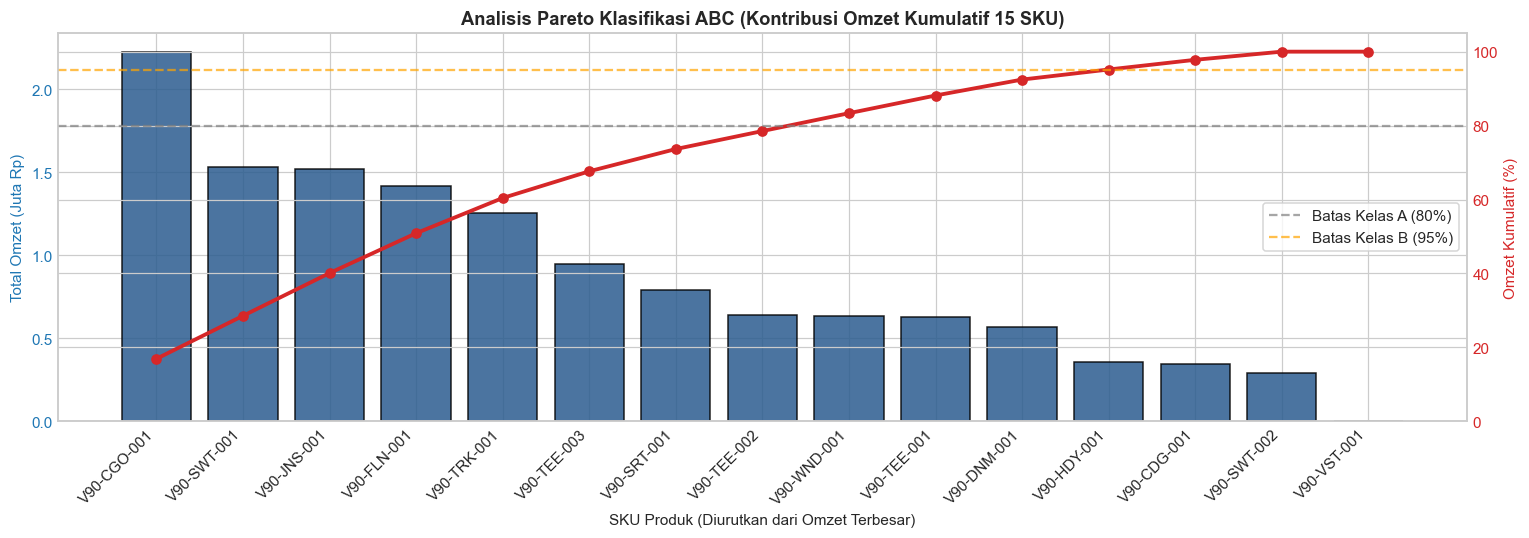

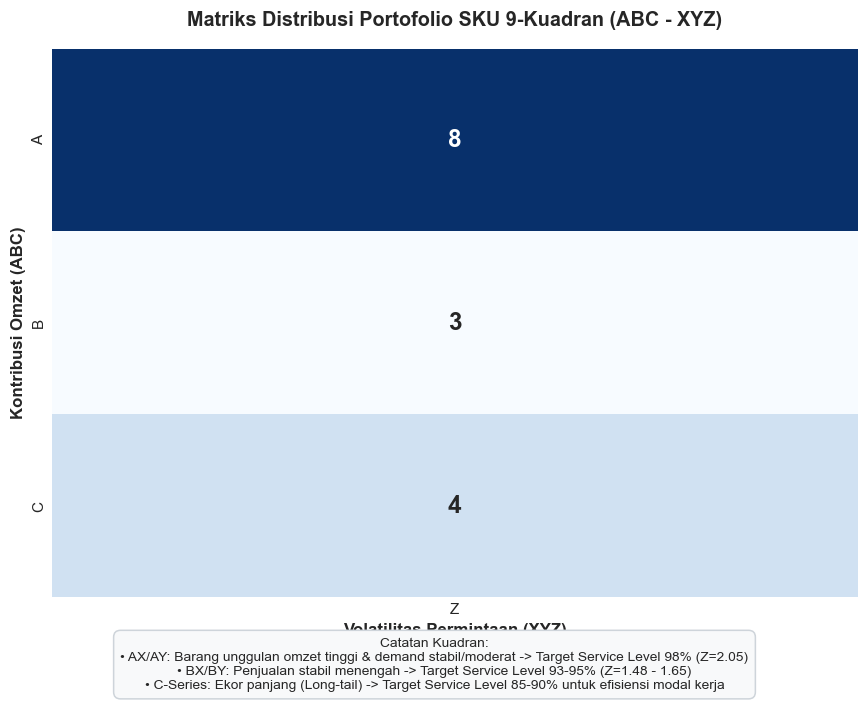

In [8]:
# Visualisasi 1: Kurva Pareto ABC
fig, ax1 = plt.subplots(figsize=(14, 5))

color = 'tab:blue'
ax1.set_xlabel('SKU Produk (Diurutkan dari Omzet Terbesar)')
ax1.set_ylabel('Total Omzet (Juta Rp)', color=color)
bars = ax1.bar(demand_profile['SKU'], demand_profile['Total_Omzet_Rp'] / 1e6, color='#2b5c8f', alpha=0.85, edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45, ha='right')

# Garis Kumulatif
ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Omzet Kumulatif (%)', color=color)
ax2.plot(demand_profile['SKU'], demand_profile['Omzet_Kumulatif_%'], color=color, marker='o', linewidth=2.5)
ax2.tick_params(axis='y', labelcolor=color)
ax2.axhline(80, color='gray', linestyle='--', alpha=0.7, label='Batas Kelas A (80%)')
ax2.axhline(95, color='orange', linestyle='--', alpha=0.7, label='Batas Kelas B (95%)')
ax2.set_ylim(0, 105)
ax2.legend(loc='center right', frameon=True)

plt.title('Analisis Pareto Klasifikasi ABC (Kontribusi Omzet Kumulatif 15 SKU)')
plt.tight_layout()
plt.show()

# Visualisasi 2: Heatmap Matriks 9 Kuadran ABC-XYZ
fig, ax = plt.subplots(figsize=(8, 6))

matrix_count = pd.crosstab(
    pd.Categorical(demand_profile['Kategori_ABC'], categories=['A', 'B', 'C']),
    pd.Categorical(demand_profile['Kategori_XYZ'], categories=['X', 'Y', 'Z'])
)

sns.heatmap(matrix_count, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws={'size': 16, 'weight': 'bold'})
ax.set_title('Matriks Distribusi Portofolio SKU 9-Kuadran (ABC - XYZ)', fontsize=13, pad=15)
ax.set_xlabel('Volatilitas Permintaan (XYZ)', fontsize=11, fontweight='bold')
ax.set_ylabel('Kontribusi Omzet (ABC)', fontsize=11, fontweight='bold')

# Keterangan panduan kuadran
plt.figtext(0.5, -0.05, 
    "Catatan Kuadran:\n"
    "• AX/AY: Barang unggulan omzet tinggi & demand stabil/moderat -> Target Service Level 98% (Z=2.05)\n"
    "• BX/BY: Penjualan stabil menengah -> Target Service Level 93-95% (Z=1.48 - 1.65)\n"
    "• C-Series: Ekor panjang (Long-tail) -> Target Service Level 85-90% untuk efisiensi modal kerja",
    wrap=True, horizontalalignment='center', fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#ced4da')
)

plt.tight_layout()
plt.show()

---
## 5. Audit Posisi Stok Saat Ini vs Titik ROP Eksisting
Kita mengevaluasi status inventaris aktif pada tabel `Persediaan` untuk memetakan:
1. Posisi stok akhir (`Stok_Akhir`) terhadap ambang batas pemesanan ulang eksisting (`Reorder_Point_Unit`).
2. Identifikasi SKU berstatus `PERLU RESTOCK`.
3. Estimasi *Days of Inventory Remaining* ($DoI = Stok\_Akhir / \mu_d$).

In [9]:
# Gabungkan status Persediaan dengan hasil kalkulasi demand
inventory_audit = pd.merge(
    df_persediaan[['SKU', 'Nama_Produk', 'Tipe_Pasokan', 'Stok_Awal_01Sep', 'Stok_Akhir', 'Safety_Stock_Unit', 'Reorder_Point_Unit', 'Status_Stok']],
    demand_profile[['SKU', 'Demand_Mean_Harian', 'Kategori_ABC', 'Kategori_XYZ', 'Segmen_ABC_XYZ', 'Target_Service_Level_%']],
    on='SKU'
)

# Hitung Days of Inventory (DoI)
inventory_audit['Days_of_Inventory'] = np.where(
    inventory_audit['Demand_Mean_Harian'] > 0,
    inventory_audit['Stok_Akhir'] / inventory_audit['Demand_Mean_Harian'],
    np.inf
)

# Selisih stok dari titik ROP
inventory_audit['Gap_ke_ROP'] = inventory_audit['Stok_Akhir'] - inventory_audit['Reorder_Point_Unit']

# Urutkan berdasarkan Gap_ke_ROP (yang paling minus/kritis di atas)
inventory_audit = inventory_audit.sort_values(by=['Gap_ke_ROP', 'Stok_Akhir']).reset_index(drop=True)

print("=== AUDIT KONDISI PERSEDIAAN & RISIKO STOCKOUT ===")
display(inventory_audit[[
    'SKU', 'Nama_Produk', 'Tipe_Pasokan', 'Stok_Akhir', 'Reorder_Point_Unit', 'Gap_ke_ROP', 
    'Days_of_Inventory', 'Status_Stok', 'Segmen_ABC_XYZ'
]])

=== AUDIT KONDISI PERSEDIAAN & RISIKO STOCKOUT ===


,SKU,Nama_Produk,Tipe_Pasokan,Stok_Akhir,Reorder_Point_Unit,Gap_ke_ROP,Days_of_Inventory,Status_Stok,Segmen_ABC_XYZ
0,V90-TEE-002,Kaos Washed Boxy,Restockable,5,8,-3,18.750000,PERLU RESTOCK,AZ
1,V90-CGO-001,Celana Cargo 90s,Restockable,5,7,-2,10.714286,PERLU RESTOCK,AZ
2,V90-DNM-001,Jaket Denim Oversize,One-off Vintage,0,0,0,0.000000,Sourcing per item,BZ
3,V90-CDG-001,Cardigan Knit Retro,One-off Vintage,0,0,0,0.000000,Sourcing per item,CZ
4,V90-SWT-001,Crewneck Colorblock,Restockable,7,7,0,19.090909,PERLU RESTOCK,AZ
5,V90-FLN-001,Kemeja Flanel Kotak,Restockable,8,8,0,18.461538,PERLU RESTOCK,AZ
6,V90-WND-001,Windbreaker Colorblock,One-off Vintage,1,0,1,7.500000,Sourcing per item,BZ
7,V90-SWT-002,Sweater Stripe Retro,One-off Vintage,1,0,1,15.000000,Sourcing per item,CZ
8,V90-VST-001,Vest Knit Retro,One-off Vintage,1,0,1,inf,Sourcing per item,CZ
9,V90-TEE-001,Kaos Graphic Grunge,Restockable,7,6,1,30.000000,Aman,BZ


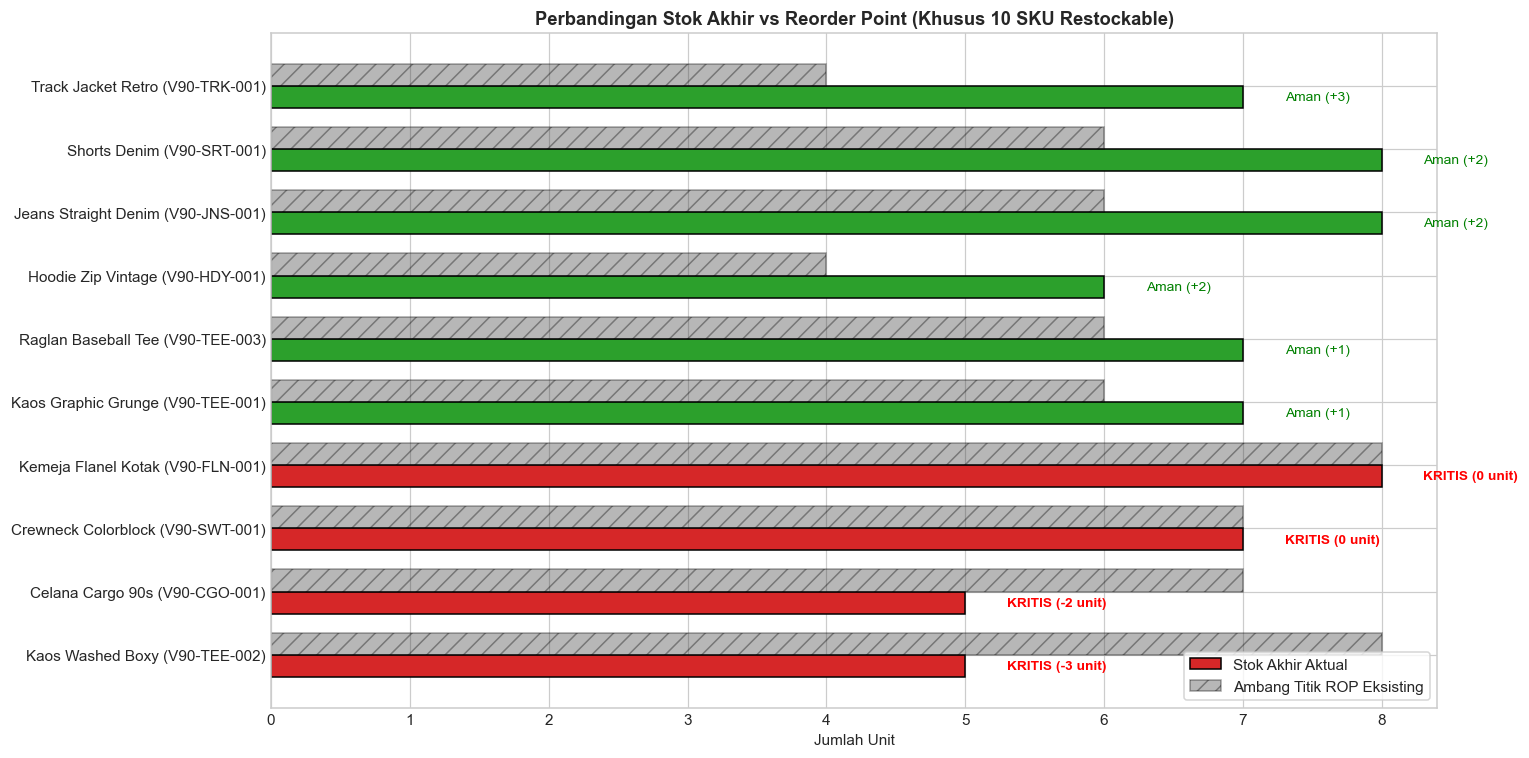

In [10]:
# Visualisasi Stok Akhir vs Reorder Point Eksisting
fig, ax = plt.subplots(figsize=(14, 7))

# Filter hanya restockable untuk perbandingan ROP yang adil
restockable_audit = inventory_audit[inventory_audit['Tipe_Pasokan'] == 'Restockable'].copy()
restockable_audit = restockable_audit.sort_values(by='Gap_ke_ROP', ascending=True)

y = np.arange(len(restockable_audit))
bar_width = 0.35

status_colors = {
    'PERLU RESTOCK': '#d62728',
    'Aman': '#2ca02c'
}
bar_colors = [status_colors.get(s, '#1f77b4') for s in restockable_audit['Status_Stok']]

bars_stok = ax.barh(y - bar_width/2, restockable_audit['Stok_Akhir'], bar_width, label='Stok Akhir Aktual', color=bar_colors, edgecolor='black')
bars_rop = ax.barh(y + bar_width/2, restockable_audit['Reorder_Point_Unit'], bar_width, label='Ambang Titik ROP Eksisting', color='#333333', alpha=0.35, edgecolor='black', hatch='//')

ax.set_yticks(y)
ax.set_yticklabels([f"{row['Nama_Produk']} ({row['SKU']})" for _, row in restockable_audit.iterrows()])
ax.set_xlabel('Jumlah Unit')
ax.set_title('Perbandingan Stok Akhir vs Reorder Point (Khusus 10 SKU Restockable)')
ax.legend(loc='lower right', frameon=True)

# Tambahkan label teks selisih
for i, (_, row) in enumerate(restockable_audit.iterrows()):
    gap = row['Gap_ke_ROP']
    stok = row['Stok_Akhir']
    rop = row['Reorder_Point_Unit']
    if gap <= 0:
        ax.text(stok + 0.3, i - bar_width/2, f'KRITIS ({gap} unit)', color='red', fontweight='bold', va='center', fontsize=9)
    else:
        ax.text(stok + 0.3, i - bar_width/2, f'Aman (+{gap})', color='green', va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 6. Ringkasan Temuan EDA & Handoff ke Tahap 2

### Temuan Kunci Tahap 1:
1. **Dua Kluster Pasokan:**
   - **10 SKU `Restockable`:** Merupakan barang pasokan berulang yang memesan dari supplier dengan batasan MOQ dan target lead time (6-10 hari).
   - **5 SKU `One-off Vintage`:** Merupakan barang kurasi per unit (*thrifting*) dengan status `Sourcing per item` dan ROP statis = 0.
2. **Volatilitas Lead Time Nyata:**
   - Standar deviasi lead time pemasok aktual mencapai **$\sigma_{LT} = 2.50$ hari**, dengan keterlambatan pengiriman mencapai +4 hari dari target. Hal ini memvalidasi bahwa perhitungan Safety Stock wajib mengintegrasikan variansi lead time supplier.
3. **Hasil Segmentasi ABC-XYZ:**
   - SKU Kelas A (penyumbang 80% omzet) seperti *Kemeja Flanel Kotak*, *Jeans Straight Denim*, dan *Hoodie Zip Vintage* memerlukan pengamanan ketersediaan tinggi (*Service Level 95% - 98%*).
   - Seluruh 15 SKU memiliki $CV_d > 1.0$ (kategori Z) karena sifat transaksi ritel harian Shopee yang *lumpy* (kadang 0 penjualan, kadang terjual beberapa unit).
4. **4 SKU Alarm Restock Saat Ini:**
   - `V90-TEE-002` (Kaos Washed Boxy): Stok 5 vs ROP 8 (Minus 3 unit)
   - `V90-FLN-001` (Kemeja Flanel Kotak): Stok 8 vs ROP 8 (Pas ROP)
   - `V90-SWT-001` (Crewneck Colorblock): Stok 7 vs ROP 7 (Pas ROP)
   - `V90-CGO-001` (Celana Cargo 90s): Stok 5 vs ROP 7 (Minus 2 unit)

---

### Rencana Eksekusi Tahap 2: Feature Engineering & Dynamic Safety Stock Formula
Pada tahap berikutnya, kita akan mengimplementasikan:
1. **King's Combined Formula untuk Safety Stock Dinamis:**
   $$SS = Z 	imes \sqrt{(\overline{LT} 	imes \sigma_d^2) + (ar{d}^2 	imes \sigma_{LT}^2)}$$
2. **Dynamic Reorder Point ($ROP_{dynamic}$):**
   $$ROP_{dynamic} = (ar{d} 	imes LT_{target}) + SS$$
3. **Penyelarasan Economic Order Quantity ($EOQ$) terhadap MOQ Supplier:**
   Membuat rekomendasi unit pemesanan PO riil yang mematuhi batas MOQ 6 supplier rekanan.